# 阶段3：历史RF与领券核销分层

固定时点2016-05-01，历史1—4月，评价5月领券且消费观察至6月15日。此Notebook保留已实际执行的计算结果、图和可复现代码；详细来源与限制见manifest.json及分层评价与触达建议.md。

## tl;dr

历史分布导出近期35天、高频3条、成熟历史多领券4条阈值；按优先级形成六个互斥群体。近期高频组后续记录率与核销用户占比较高，但不能把自然核销差异解释成触达增量。未知历史只为回溯评价补入，不是已知的5月1日名单。

## Context & Methods

历史事件严格早于5月1日，领券按Date_received、消费按Date；成熟历史领券最晚4月15日，成功结果也需在时点前可见。领券未核销Date缺失是正常状态。

### Key Assumptions

频次是原始记录数，重复保留，不是订单数；没有金额，不称完整RFM。未知历史不等于新用户，未观察消费不等于从未消费。评价只限5月领券者，同用户多次领券在用户级重抽样中保留相关性。95%区间假设用户之间独立，条件于样本，不作因果或多重比较显著性检验。

## Data

来源SQL：项目o2o_work/sql中的08_user_features_asof.sql、09_user_segments.sql、10_user_segment_evaluation.sql。每个结果绑定本次运行目录。

In [1]:
from pathlib import Path
import csv,json
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display,Markdown
WORK=next(p for p in [Path.cwd()/'o2o_work',Path.cwd(),*Path.cwd().parents] if (p/'config/analysis.json').exists())
RESULT=WORK/'results/stage3/runs/20261015T154103504261'
FIG=RESULT/'figures';FIG.mkdir(exist_ok=True)
manifest=json.loads((RESULT/'manifest.json').read_text());rules=json.loads((RESULT/'segmentation_rules.json').read_text())
def number_or_nan(value): return float('nan') if value in ('',None) else float(value)
def load(table):
    with (RESULT/(table+'.csv')).open(encoding='utf-8',newline='') as f:return list(csv.DictReader(f))
ORDER=['unknown_history','high_receipt_zero_redemption','no_observed_consumption','recent_high_frequency','recent_low_frequency','not_recent_consumption']
NAMES=rules['names']
SHORT=['Unknown history','Many receipts / zero use','History / no consumption','Recent / high frequency','Recent / low frequency','Not recent consumption']
LABELS={'segment_id':'互斥群体','universe_users':'分层用户','mature_receipt_users':'5月领券用户','mature_receipt_records':'5月领券','redeemed15_records':'15日核销','record_redemption_rate15':'记录率','redeemed15_users':'核销用户','redemption_user_share15':'用户占比','mean_within_user_redemption_rate15':'用户均权率','feature':'特征','users':'用户数','q25':'Q25','q50':'Q50','q75':'Q75','q90':'Q90','condition':'优先命中条件','priority':'优先级','segment_name':'群体','user_id':'匿名用户','history_consumption_records':'历史消费','history_mature_receipt_records':'历史成熟领券','history_redeemed15_records':'历史核销','recency_days':'最近消费间隔'}
def table(name,cols,limit=12):
    values=load(name)[:limit]
    def fmt(k,v):
        if not v:return '—'
        if k=='segment_id':return NAMES.get(v,v)
        if k=='feature':return {'history_active_days':'历史活跃天数（天）','history_consumption_records':'历史消费频次（记录）','history_mature_receipt_records':'历史成熟领券频次（记录）','history_redemption_rate15':'历史15日核销率（比例）','recency_days':'最近消费间隔（天）'}.get(v,v)
        if 'rate' in k or 'share' in k:return format(float(v),'.2%')
        if k.endswith(('_records','_users')) or k in ['users','universe_users']:return format(float(v),',.0f')
        if k in ['q25','q50','q75','q90','recency_days']:return format(float(v),'.2f')
        return v
    text='| '+' | '.join(LABELS.get(k,k) for k in cols)+' |\n|'+ '|'.join(['---']*len(cols))+'|\n'
    text+='\n'.join('| '+' | '.join(fmt(k,r[k]) for k in cols)+' |' for r in values)
    display(Markdown(text))
def finish(fig,name):
    fig.tight_layout();fig.savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight');plt.show()
def style(ax):
    ax.grid(axis='x',color='#e3e5e8',linewidth=.7);ax.set_axisbelow(True);ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.facecolor':'white'})
BLUE='#3266a8';GOLD='#c88a31'
print('As-of:',rules['asof_date'],'; historical feature rules frozen before May evaluation.')
print('Source stage1 run:',manifest['source_stage1_run'])
assert rules['rule_selection_uses_may_outcomes'] is False


As-of: 2016-05-01 ; historical feature rules frozen before May evaluation.
Source stage1 run: 20261015T154031143321


## Results

### 1. 历史分布与规则

RF图仅使用历史有消费的用户；分位数表按每个特征对应的历史群体统计，具体过滤见feature_distribution.csv。完整阈值依据见segmentation_rules.json；零历史消费与未知历史保留单独群体。

| 特征 | 用户数 | Q25 | Q50 | Q75 | Q90 |
|---|---|---|---|---|---|
| 历史活跃天数（天） | 433,113 | 1.00 | 1.00 | 2.00 | 4.00 |
| 历史消费频次（记录） | 157,049 | 1.00 | 1.00 | 3.00 | 6.00 |
| 历史成熟领券频次（记录） | 347,147 | 1.00 | 1.00 | 2.00 | 4.00 |
| 历史15日核销率（比例） | 347,147 | 0.00 | 0.00 | 0.00 | 0.00 |
| 最近消费间隔（天） | 157,049 | 12.00 | 35.00 | 64.00 | 96.00 |

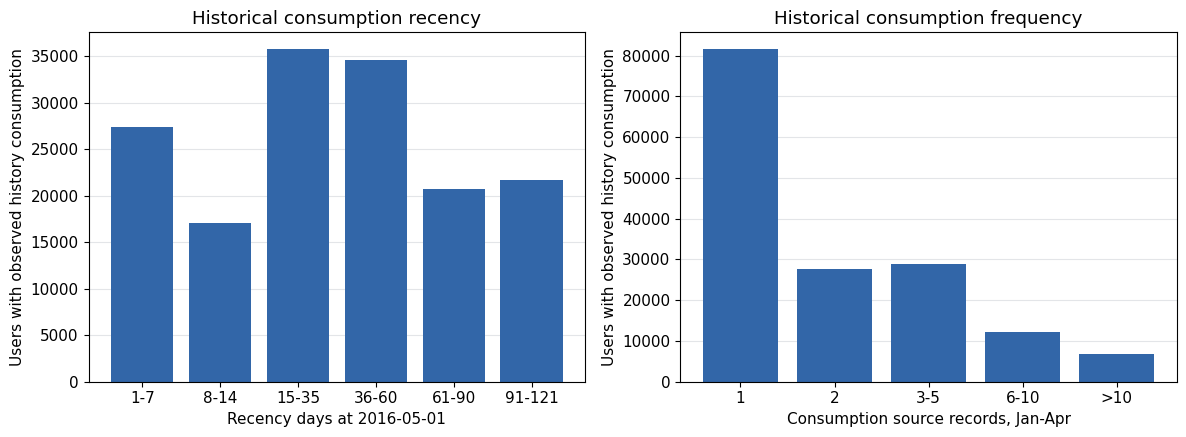

| 优先级 | 群体 | 优先命中条件 |
|---|---|---|
| 1 | 未知历史 | NOT has_observed_history |
| 2 | 历史多领券零核销 | history_mature_receipt_records>=4 AND history_redeemed15_records=0 |
| 3 | 有历史但无已观察消费 | history_consumption_records=0 |
| 4 | 近期高频消费 | recency_days<=35 AND history_consumption_records>=3 |
| 5 | 近期低频消费 | recency_days<=35 |
| 6 | 非近期消费 | remaining history-consumption users |

In [2]:
table('feature_distribution',['feature','users','q25','q50','q75','q90'])
data=load('feature_bins')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,feature,title,xlabel in [(axes[0],'recency_days','Historical consumption recency','Recency days at 2016-05-01'),(axes[1],'history_consumption_records','Historical consumption frequency','Consumption source records, Jan-Apr')]:
    subset=sorted([r for r in data if r['feature']==feature],key=lambda r:int(r['bin_order']))
    ax.bar([r['bin_label'] for r in subset],[int(r['users']) for r in subset],color=BLUE)
    ax.set_title(title);ax.set_xlabel(xlabel);ax.set_ylabel('Users with observed history consumption');ax.grid(axis='y',color='#e3e5e8');ax.set_axisbelow(True)
finish(fig,'01_historical_rf')
table('rule_catalog',['priority','segment_name','condition'])


规则顺序重要：成熟历史领券≥4且零核销的用户优先单列，因此其他RF组不是所有近期消费用户。历史核销率只用最晚4月15日领券，未成熟券不参与分子分母。

### 2. 分层覆盖与5月领券覆盖

分层总体包含历史用户与5月评价用户的并集。未知历史组的5月覆盖100%由构造造成，不是业务优势。

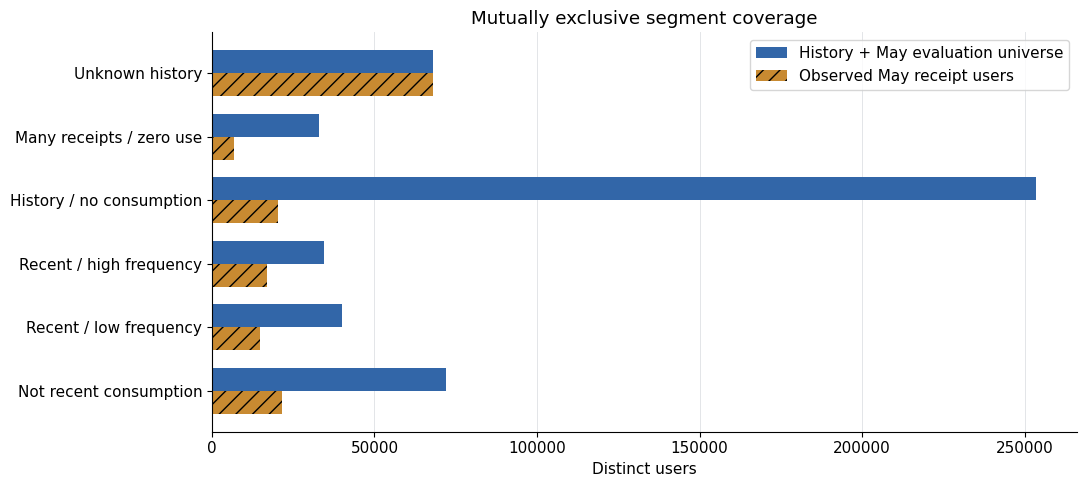

| 互斥群体 | 分层用户 | 5月领券用户 | 5月领券 | 15日核销 | 记录率 |
|---|---|---|---|---|---|
| 历史多领券零核销 | 33,053 | 6,738 | 10,913 | 915 | 8.38% |
| 有历史但无已观察消费 | 253,448 | 20,375 | 27,755 | 1,675 | 6.03% |
| 非近期消费 | 71,876 | 21,613 | 30,501 | 2,511 | 8.23% |
| 近期高频消费 | 34,588 | 17,032 | 37,941 | 7,855 | 20.70% |
| 近期低频消费 | 40,148 | 14,753 | 24,145 | 2,578 | 10.68% |
| 未知历史 | 67,928 | 67,928 | 84,093 | 6,046 | 7.19% |

In [3]:
data={r['segment_id']:r for r in load('segment_evaluation')}
y=list(range(len(ORDER)))
fig,ax=plt.subplots(figsize=(11,5))
ax.barh([i-.18 for i in y],[int(data[k]['universe_users']) for k in ORDER],height=.36,color=BLUE,label='History + May evaluation universe')
ax.barh([i+.18 for i in y],[int(data[k]['mature_receipt_users']) for k in ORDER],height=.36,color=GOLD,hatch='//',label='Observed May receipt users')
ax.set_yticks(y,SHORT);ax.invert_yaxis();ax.set_xlabel('Distinct users');ax.set_title('Mutually exclusive segment coverage');ax.legend();style(ax)
finish(fig,'02_segment_coverage')
table('segment_evaluation',['segment_id','universe_users','mature_receipt_users','mature_receipt_records','redeemed15_records','record_redemption_rate15'])
assert sum(int(r['mature_receipt_records']) for r in data.values())==215348
assert sum(int(r['redeemed15_records']) for r in data.values())==21580
assert sum(int(r['mature_receipt_users']) for r in data.values())==148439
assert sum(int(r['redeemed15_users']) for r in data.values())==14860


### 3. 后续记录率与用户占比及不确定性

两种率的分母不同；误差线为按用户重抽样的95%百分位区间，不是随机干预效果区间。

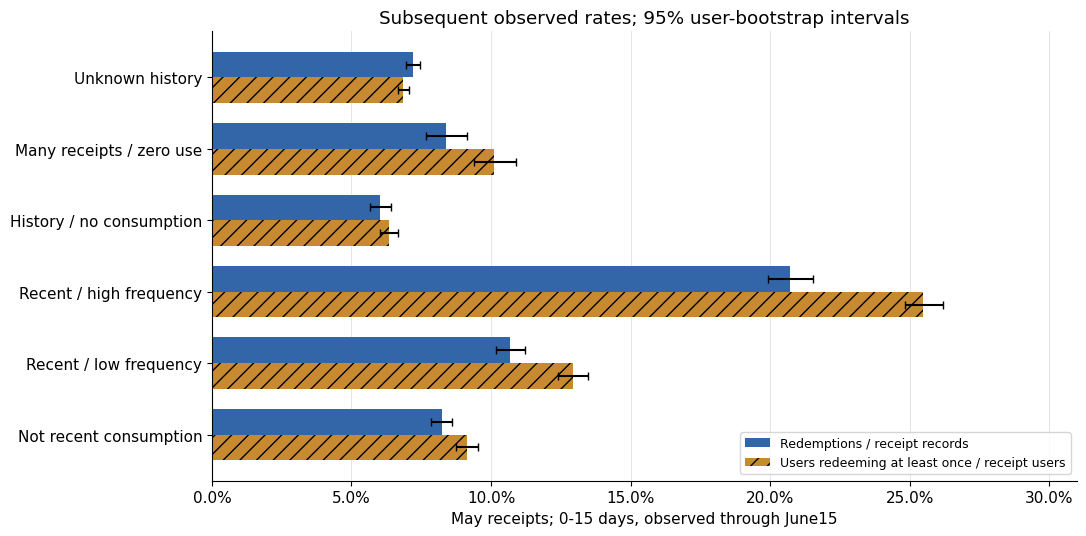

| 互斥群体 | 5月领券用户 | 核销用户 | 用户占比 |
|---|---|---|---|
| 历史多领券零核销 | 6,738 | 681 | 10.11% |
| 有历史但无已观察消费 | 20,375 | 1,292 | 6.34% |
| 非近期消费 | 21,613 | 1,977 | 9.15% |
| 近期高频消费 | 17,032 | 4,342 | 25.49% |
| 近期低频消费 | 14,753 | 1,908 | 12.93% |
| 未知历史 | 67,928 | 4,660 | 6.86% |

In [4]:
ci={(r['segment_id'],r['metric']):r for r in load('segment_bootstrap_intervals')}
fig,ax=plt.subplots(figsize=(11,5.5))
for metric,offset,color,hatch,label in [('record_redemption_rate15',-.18,BLUE,'','Redemptions / receipt records'),('redemption_user_share15',.18,GOLD,'//','Users redeeming at least once / receipt users')]:
    points=[number_or_nan(ci[k,metric]['point_estimate']) for k in ORDER]
    low=[p-number_or_nan(ci[k,metric]['ci95_low']) for k,p in zip(ORDER,points)]
    high=[number_or_nan(ci[k,metric]['ci95_high'])-p for k,p in zip(ORDER,points)]
    ax.barh([i+offset for i in y],points,height=.36,color=color,hatch=hatch,xerr=[low,high],capsize=3,label=label)
ax.set_yticks(y,SHORT);ax.invert_yaxis();ax.set_xlabel('May receipts; 0-15 days, observed through June15');ax.set_title('Subsequent observed rates; 95% user-bootstrap intervals');ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_xlim(0,.31);ax.legend(loc='lower right',fontsize=9);style(ax)
for i,k in enumerate(ORDER):
    if ci[k,'record_redemption_rate15']['point_estimate'] in ('',None):ax.text(.005,i,'N/A (no May receipts)',va='center')
finish(fig,'03_evaluation_rates')
table('segment_evaluation',['segment_id','mature_receipt_users','redeemed15_users','redemption_user_share15'])


### 4. 多次领券的权重差异

用户均权率先算每人核销量/领券量再平均；它不能替代记录率，也不等于核销用户占比。

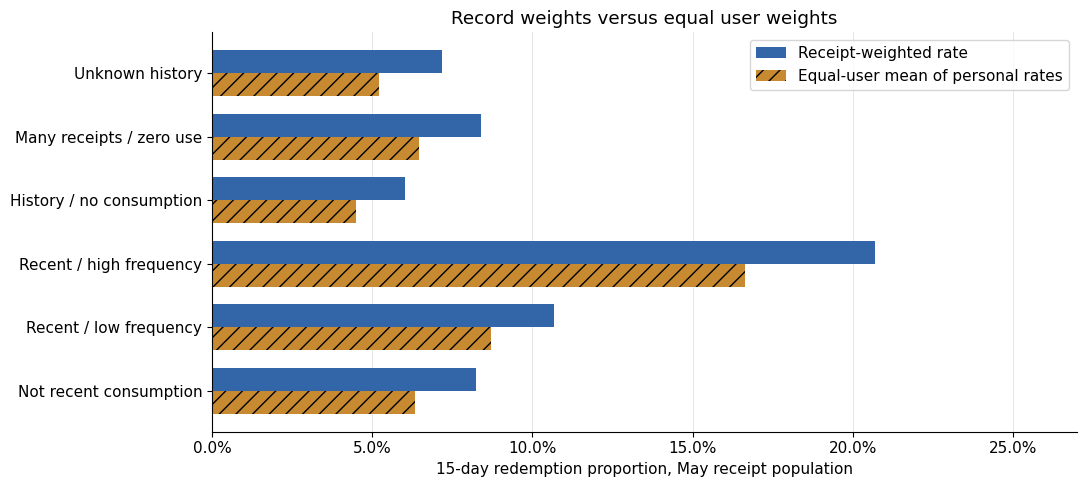

| 互斥群体 | 记录率 | 用户均权率 | 用户占比 |
|---|---|---|---|
| 历史多领券零核销 | 8.38% | 6.45% | 10.11% |
| 有历史但无已观察消费 | 6.03% | 4.51% | 6.34% |
| 非近期消费 | 8.23% | 6.35% | 9.15% |
| 近期高频消费 | 20.70% | 16.64% | 25.49% |
| 近期低频消费 | 10.68% | 8.72% | 12.93% |
| 未知历史 | 7.19% | 5.22% | 6.86% |

In [5]:
data={r['segment_id']:r for r in load('segment_user_evaluation')}
fig,ax=plt.subplots(figsize=(11,5))
for key,offset,color,hatch,label in [('record_redemption_rate15',-.18,BLUE,'','Receipt-weighted rate'),('mean_within_user_redemption_rate15',.18,GOLD,'//','Equal-user mean of personal rates')]:
    ax.barh([i+offset for i in y],[number_or_nan(data[k][key]) for k in ORDER],height=.36,color=color,hatch=hatch,label=label)
ax.set_yticks(y,SHORT);ax.invert_yaxis();ax.set_xlabel('15-day redemption proportion, May receipt population');ax.set_title('Record weights versus equal user weights');ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_xlim(0,.27);ax.legend();style(ax)
for i,k in enumerate(ORDER):
    if data[k]['record_redemption_rate15'] in ('',None):ax.text(.005,i,'N/A (no May receipts)',va='center')
finish(fig,'04_user_weight_comparison')
table('segment_user_evaluation',['segment_id','record_redemption_rate15','mean_within_user_redemption_rate15','redemption_user_share15'])


### 5. 匿名样例、未来扰动与重复敏感性

每组一名样例的历史事件明细保留record_id，可回查源文件。未知历史样例没有历史事件。未来扰动检验只比较历史特征，5月评价群体成员资格单独处理。

## Takeaways

近期高频组后续记录核销、核销用户占比和用户均权率都较高，但高自然核销不代表最高营销增量，也可能有过度补贴风险。建议先用不触达对照、小规模券/提醒实验验证。历史多领券零核销组未来仍会核销，不能称永远无效。未知历史不等于新用户；在5月1日没有这些用户的已观察名单，不能倒推成当时触达计划。完整六组建议、证据和限制见分层评价与触达建议.md。

In [6]:
print('Notebook checks passed; this is RF/coupon behavior segmentation, not monetary RFM.')

Notebook checks passed; this is RF/coupon behavior segmentation, not monetary RFM.
